# Eksploracyjna analiza danych Wikipedii

Notebook analizuje pliki JSON z `data/raw/wikipedia/`. Dane zawierają historię rewizji stron Wikipedii pobraną przez scraper projektu.

In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

DATA_DIR = Path("data/raw/wikipedia")
files = sorted(DATA_DIR.glob("*.json"))
if not files:
    raise FileNotFoundError(f"Nie znaleziono plików JSON w {DATA_DIR.resolve()}")

len(files), [file.name for file in files]

(8,
 ['COVID-19.json',
  'Globalne_ocieplenie.json',
  'Kwas_askorbinowy.json',
  'Lekarz.json',
  'Medycyna.json',
  'Szczepionka.json',
  'Zespół_nabytego_niedoboru_odporności.json',
  'Zmiana_klimatu.json'])

## Wczytanie i normalizacja danych

Każdy rekord odpowiada jednej rewizji. Z treści rewizji wyliczamy cechy ilościowe, aby dalsza analiza nie musiała wielokrotnie przetwarzać dużych pól tekstowych.

In [2]:
records = []
page_summary = []

for path in files:
    with path.open(encoding="utf-8") as file:
        payload = json.load(file)

    url = payload.get("url")
    edits = payload.get("edits", [])
    page_title = url.rsplit("/", 1)[-1] if url else path.stem
    page_title = page_title.replace("_", " ")

    for edit_number, edit in enumerate(edits, start=1):
        content = edit.get("new_content") or ""
        records.append({
            "page": page_title,
            "url": url,
            "revision_number": edit_number,
            "introduced": edit.get("introduced"),
            "comment_field_present": "comment" in edit,
            "comment": edit.get("comment", ""),
            "content_chars": len(content),
            "content_lines": content.count("\n") + (1 if content else 0),
            "content_words": len(re.findall(r"\b\w+\b", content, flags=re.UNICODE)),
            "links": len(re.findall(r"\[\[.*?\]\]", content, flags=re.DOTALL)),
            "templates": len(re.findall(r"\{\{.*?\}\}", content, flags=re.DOTALL)),
        })

    page_summary.append({
        "page": page_title,
        "url": url,
        "revisions": len(edits),
        "file_mb": path.stat().st_size / 1024**2,
    })

df = pd.DataFrame(records)
df["introduced"] = pd.to_datetime(df["introduced"], utc=True, errors="coerce")
df["comment"] = df["comment"].fillna("").astype(str).str.strip()
df["year"] = df["introduced"].dt.year
df["month"] = df["introduced"].dt.to_period("M").astype("string")
pages = pd.DataFrame(page_summary).sort_values("revisions", ascending=False)
df.head()

C:\Users\sosog\AppData\Local\Temp\ipykernel_63000\2908881022.py:40: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["introduced"].dt.to_period("M").astype("string")


,page,url,revision_number,introduced,comment_field_present,comment,content_chars,content_lines,content_words,links,templates,year,month
0,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,1,2020-02-12 08:35:29+00:00,True,COVID-19 start,5562,75,729,19,16,2020,2020-02
1,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,2,2020-02-12 08:37:22+00:00,True,d,5816,75,774,19,17,2020,2020-02
2,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,3,2020-02-12 14:52:23+00:00,True,"[[WP:SK]], drobne techniczne",5809,74,772,19,17,2020,2020-02
3,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,4,2020-02-12 20:32:49+00:00,True,kat.,5835,74,774,20,17,2020,2020-02
4,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,5,2020-02-13 08:29:40+00:00,True,"akt., drobne redakcyjne",5867,74,779,20,17,2020,2020-02


## Rozmiar zbioru i kontrola jakości

In [3]:
quality = pd.Series({
    "liczba plików / stron": len(files),
    "liczba rewizji": len(df),
    "najwcześniejsza rewizja": df["introduced"].min(),
    "najpóźniejsza rewizja": df["introduced"].max(),
    "brakujące daty": int(df["introduced"].isna().sum()),
    "puste treści": int((df["content_chars"] == 0).sum()),
})
display(quality.to_frame("wartość"))
display(pages)
display(df.isna().sum().to_frame("braki"))

,wartość
liczba plików / stron,8
liczba rewizji,2222
najwcześniejsza rewizja,2016-01-10 14:24:04+00:00
najpóźniejsza rewizja,2026-10-13 15:02:41+00:00
brakujące daty,0
puste treści,6


,page,url,revisions,file_mb
0,COVID-19,https://pl.wikipedia.org/wiki/COVID-19,853,55.709651
6,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,https://pl.wikipedia.org/wiki/Zesp%C3%B3%C5%82_nabytego_niedoboru_odporno%C5%9Bci,320,71.973558
5,Szczepionka,https://pl.wikipedia.org/wiki/Szczepionka,299,19.532502
1,Globalne ocieplenie,https://pl.wikipedia.org/wiki/Globalne_ocieplenie,279,32.140097
3,Lekarz,https://pl.wikipedia.org/wiki/Lekarz,197,4.585526
2,Kwas askorbinowy,https://pl.wikipedia.org/wiki/Kwas_askorbinowy,151,6.069566
7,Zmiana klimatu,https://pl.wikipedia.org/wiki/Zmiana_klimatu,75,1.799268
4,Medycyna,https://pl.wikipedia.org/wiki/Medycyna,48,0.309065


,braki
page,0
url,0
revision_number,0
introduced,0
comment_field_present,0
comment,0
content_chars,0
content_lines,0
content_words,0
links,0


## Porównanie stron

Liczba rewizji jest przybliżeniem aktywności edycyjnej w zakresie dat pobranym przez scraper. Rozmiar treści opisuje stan strony w poszczególnych rewizjach, a nie rozmiar pojedynczej zmiany.

,page,revisions,mean_chars,median_chars,max_chars,mean_links
0,COVID-19,853,66215.0,73537.0,102471,122.3
6,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,320,226905.0,257011.0,264006,499.0
5,Szczepionka,299,65724.0,68384.0,85770,178.7
1,Globalne ocieplenie,279,116550.0,117039.0,129597,311.7
3,Lekarz,197,23174.0,21876.0,33459,262.5
2,Kwas askorbinowy,151,40324.0,42785.0,49461,186.3
7,Zmiana klimatu,75,23897.0,23367.0,28591,94.9
4,Medycyna,48,6291.0,6306.0,6429,140.5


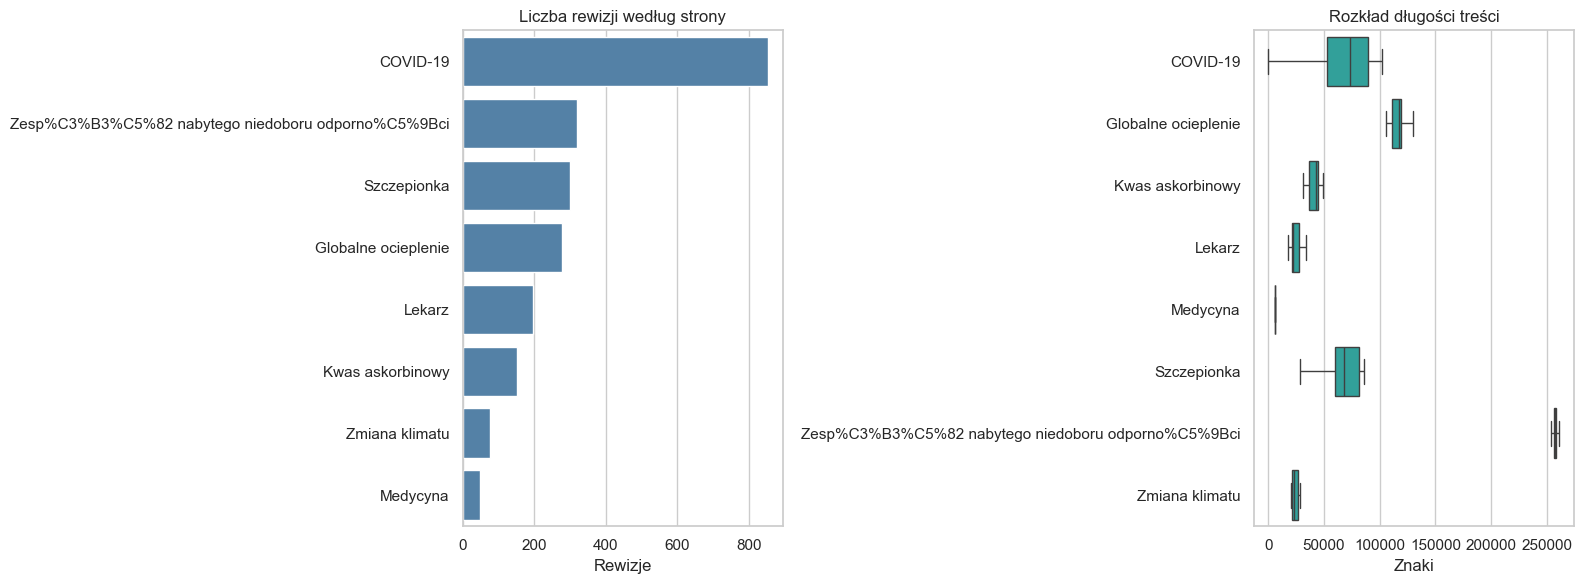

In [4]:
page_metrics = (
    df.groupby("page", as_index=False)
      .agg(
          revisions=("page", "size"),
          mean_chars=("content_chars", "mean"),
          median_chars=("content_chars", "median"),
          max_chars=("content_chars", "max"),
          mean_links=("links", "mean"),
      )
      .sort_values("revisions", ascending=False)
)
display(page_metrics.round({"mean_chars": 0, "median_chars": 0, "max_chars": 0, "mean_links": 1}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=page_metrics, y="page", x="revisions", ax=axes[0], color="steelblue")
axes[0].set(title="Liczba rewizji według strony", xlabel="Rewizje", ylabel="")
sns.boxplot(data=df, y="page", x="content_chars", ax=axes[1], color="lightseagreen", showfliers=False)
axes[1].set(title="Rozkład długości treści", xlabel="Znaki", ylabel="")
plt.tight_layout()

## Aktywność w czasie

C:\Users\sosog\AppData\Local\Temp\ipykernel_63000\1105884960.py:6: FutureWarning: DataFrameGroupBy.resample operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .size()


page,COVID-19,Globalne ocieplenie,Kwas askorbinowy,Lekarz,Medycyna,Szczepionka,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,Zmiana klimatu
introduced,,,,,,,,
2016-12-31 00:00:00+00:00,0,12,33,21,6,9,28,1
2017-12-31 00:00:00+00:00,0,9,21,11,3,90,50,2
2018-12-31 00:00:00+00:00,0,48,35,10,7,37,32,10
2019-12-31 00:00:00+00:00,0,26,8,17,4,66,20,10
2020-12-31 00:00:00+00:00,619,43,13,25,1,25,85,12
2021-12-31 00:00:00+00:00,141,36,5,32,13,33,22,12
2022-12-31 00:00:00+00:00,52,37,6,20,5,11,8,9
2023-12-31 00:00:00+00:00,11,24,0,18,4,10,11,3
2024-12-31 00:00:00+00:00,13,21,16,22,2,6,43,2


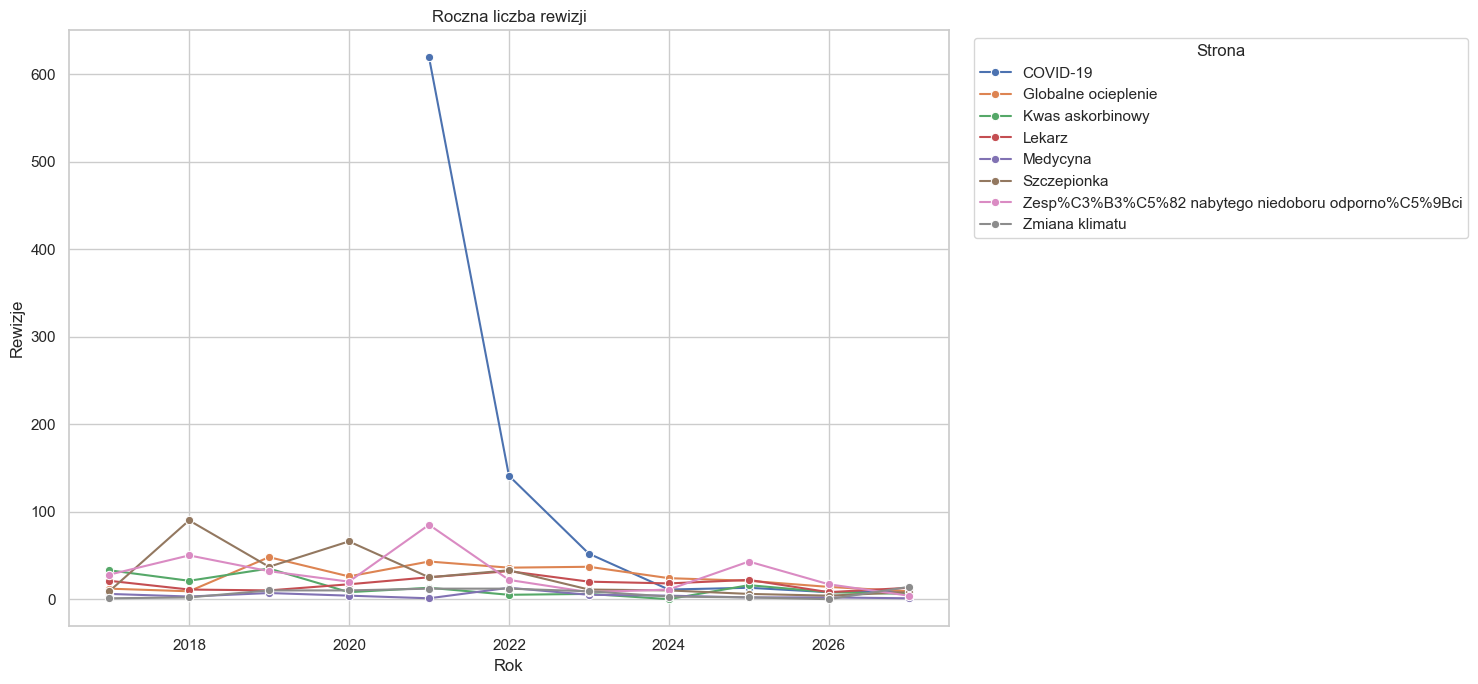

In [5]:
activity = (
    df.dropna(subset=["introduced"])
      .set_index("introduced")
      .groupby("page")
      .resample("YE")
      .size()
      .rename("revisions")
      .reset_index()
)

plt.figure(figsize=(15, 7))
sns.lineplot(data=activity, x="introduced", y="revisions", hue="page", marker="o")
plt.title("Roczna liczba rewizji")
plt.xlabel("Rok")
plt.ylabel("Rewizje")
plt.legend(title="Strona", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

display(activity.pivot(index="introduced", columns="page", values="revisions").fillna(0).astype(int))

## Zależności między cechami rewizji

Macierz korelacji pokazuje, czy większe treści mają zwykle więcej linków lub szablonów. Korelacja nie oznacza związku przyczynowego.

,count,mean,std,min,25%,50%,75%,95%,max
content_chars,2222.0,87312.542754,71464.953350,0.0,39358.00,72214.0,102102.00,257761.00,264006.0
content_lines,2222.0,372.435644,275.895871,0.0,234.00,317.0,422.75,724.00,1757.0
content_words,2222.0,11885.382988,9510.176134,0.0,5337.25,10332.0,14485.00,34002.95,35323.0
links,2222.0,224.198920,145.966706,0.0,129.00,166.5,289.00,563.00,583.0
templates,2222.0,197.022952,180.652467,0.0,79.00,174.0,196.00,647.00,680.0


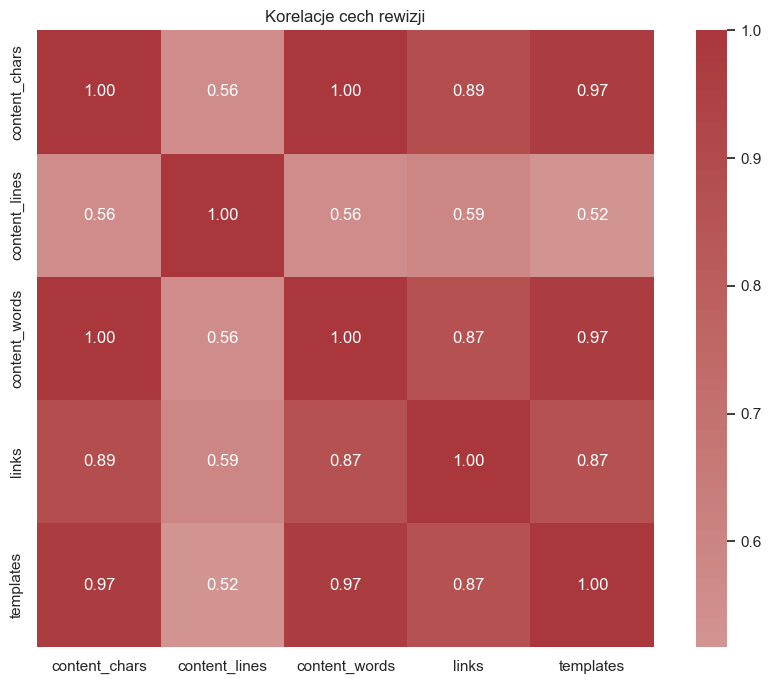

In [6]:
numeric_columns = ["content_chars", "content_lines", "content_words", "links", "templates"]
corr = df[numeric_columns].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Korelacje cech rewizji")
plt.tight_layout()

display(df[numeric_columns].describe(percentiles=[.25, .5, .75, .95]).T)

## Największe obserwowane wersje stron

Poniższa tabela pomaga zidentyfikować rewizje o największej objętości tekstu i potencjalne obserwacje odstające.

In [7]:
largest_revisions = (
    df.nlargest(15, "content_chars")
      [["page", "introduced", "revision_number", "content_chars", "content_words", "links", "templates"]]
      .reset_index(drop=True)
)
display(largest_revisions.round({"content_chars": 0, "content_words": 0}))

,page,introduced,revision_number,content_chars,content_words,links,templates
0,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-06-28 11:13:37+00:00,309,264006,35323,577,680
1,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-06-28 11:11:34+00:00,308,263987,35322,576,680
2,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-06-28 11:02:38+00:00,307,263915,35310,576,679
3,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-06-28 11:00:14+00:00,306,263849,35302,575,678
4,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-10-19 11:33:06+00:00,314,263712,35272,578,678
5,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-06-27 23:14:51+00:00,305,263701,35287,568,678
6,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2026-03-12 15:32:16+00:00,318,263663,35263,578,677
7,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2026-01-09 13:32:56+00:00,317,263650,35263,578,677
8,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-09-01 21:32:49+00:00,313,263649,35263,578,677
9,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,2025-10-19 12:06:29+00:00,315,263649,35263,578,677


## Wnioski do dalszej analizy

- Porównaj aktywność stron z tematyką i wydarzeniami zewnętrznymi.
- Do analizy zmian między rewizjami oblicz różnice tekstowe, zamiast porównywać tylko długości.
- Sprawdź obserwacje odstające przed modelowaniem, ponieważ strony różnią się skalą i liczbą rewizji.
- Jeśli potrzebne są statystyki autorów, scraper musi zapisywać dodatkowo identyfikator użytkownika rewizji.

## Analiza komentarzy (opisów zmian)

Wikipedia przechowuje komentarz redaktora przy każdej rewizji. Jest to krótki opis wykonanej zmiany, a nie komentarz dyskusyjny z karty „Dyskusja”. Sekcja analizuje pokrycie komentarzami, ich długość, aktywność w czasie oraz najczęstsze słowa. Aby uzyskać kompletne wyniki, pobierz dane ponownie po aktualizacji scrapera.

In [8]:
if "comment" not in df.columns:
    raise ValueError(
        "Brak kolumny 'comment'. Uruchom ponownie pobieranie danych Wikipedii "
        "po aktualizacji scrapera."
    )

df["comment"] = df["comment"].fillna("").astype(str).str.strip()
df["has_comment"] = df["comment"].ne("")
df["comment_chars"] = df["comment"].str.len()
df["comment_words"] = df["comment"].str.findall(r"\b\w+\b").str.len()

comment_quality = pd.Series({
    "rewizje ogółem": len(df),
    "rewizje z polem comment": int(df["comment_field_present"].sum()),
    "brak pola comment": int((~df["comment_field_present"]).sum()),
    "rewizje z komentarzem": int(df["has_comment"].sum()),
    "odsetek rewizji z komentarzem (%)": 100 * df["has_comment"].mean(),
    "mediana znaków komentarza": df.loc[df["has_comment"], "comment_chars"].median(),
    "mediana słów komentarza": df.loc[df["has_comment"], "comment_words"].median(),
})
display(comment_quality.to_frame("wartość").round(1))

comment_by_page = (
    df.groupby("page", as_index=False)
      .agg(
          revisions=("revision_number", "size"),
          comments=("has_comment", "sum"),
          comment_rate=("has_comment", "mean"),
          median_comment_chars=("comment_chars", lambda values: values[values > 0].median()),
      )
      .sort_values("comment_rate", ascending=False)
)
comment_by_page["comment_rate"] *= 100
display(comment_by_page.round({"comment_rate": 1, "median_comment_chars": 1}))

,wartość
rewizje ogółem,2222.0
rewizje z polem comment,2222.0
brak pola comment,0.0
rewizje z komentarzem,2047.0
odsetek rewizji z komentarzem (%),92.1
mediana znaków komentarza,42.0
mediana słów komentarza,5.0


,page,revisions,comments,comment_rate,median_comment_chars
2,Kwas askorbinowy,151,145,96.0,46.0
1,Globalne ocieplenie,279,262,93.9,46.0
4,Medycyna,48,45,93.8,64.0
6,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,320,296,92.5,41.5
7,Zmiana klimatu,75,69,92.0,53.0
5,Szczepionka,299,274,91.6,48.5
0,COVID-19,853,779,91.3,36.0
3,Lekarz,197,177,89.8,38.0


,słowo,liczba
0,user,452
1,drobne,361
2,special,302
3,wersji,294
4,contributions,290
5,talk,282
6,dyskusja,280
7,wycofano,211
8,autor,170
9,przywróconej,169


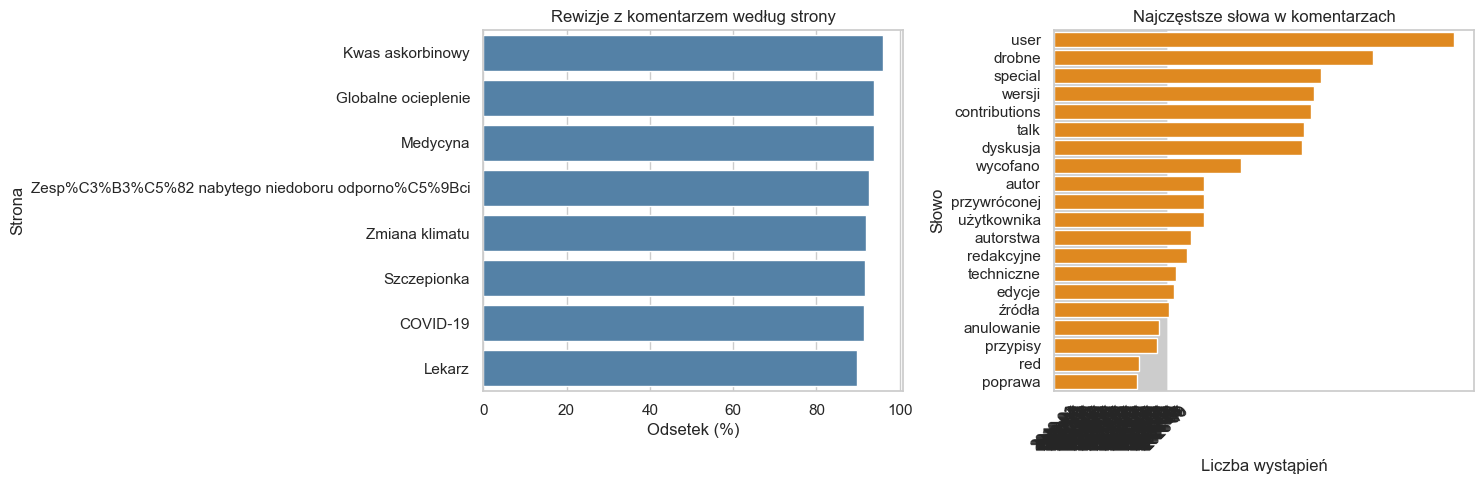

In [9]:
comment_timeline = (
    df.groupby("month", as_index=False)
      .agg(revisions=("revision_number", "size"), comments=("has_comment", "sum"))
)
comment_timeline["comment_rate"] = (
    100 * comment_timeline["comments"] / comment_timeline["revisions"]
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=comment_by_page, y="page", x="comment_rate", ax=axes[0], color="steelblue")
axes[0].set(title="Rewizje z komentarzem według strony", xlabel="Odsetek (%)", ylabel="Strona")
sns.lineplot(data=comment_timeline, x="month", y="comment_rate", marker="o", ax=axes[1])
axes[1].tick_params(axis="x", rotation=45)
axes[1].set(title="Odsetek komentarzy w czasie", xlabel="Miesiąc", ylabel="Odsetek (%)")
plt.tight_layout()

stopwords = {
    "i", "a", "o", "w", "z", "na", "do", "ze", "że", "to", "jest", "oraz",
    "dla", "nie", "się", "po", "od", "jak", "by", "lub", "the", "of", "and",
}
tokens = (
    df.loc[df["has_comment"], "comment"]
      .str.lower()
      .str.findall(r"[a-ząćęłńóśźż]{3,}")
      .explode()
      .dropna()
)
top_comment_words = (
    tokens[~tokens.isin(stopwords)]
    .value_counts()
    .head(20)
    .rename_axis("słowo")
    .reset_index(name="liczba")
)
display(top_comment_words)
if not top_comment_words.empty:
    sns.barplot(data=top_comment_words, y="słowo", x="liczba", color="darkorange")
    plt.title("Najczęstsze słowa w komentarzach")
    plt.xlabel("Liczba wystąpień")
    plt.ylabel("Słowo")
    plt.tight_layout()
else:
    print("Brak komentarzy w danych. Pobierz dane ponownie po aktualizacji scrapera.")

## Odniesienia i źródła przywoływane w komentarzach

Z komentarzy wyciągamy zewnętrzne adresy URL oraz skróty stron/projektów Wikipedii, np. `[[WP:SK]]`, `[[WPT:...]]` i `[[WT:...]]`. Domeny URL-i pokazują, do jakich serwisów prowadzą odniesienia. Skróty Wikipedii są raportowane osobno, ponieważ nie są źródłami zewnętrznymi.

In [10]:
from urllib.parse import urlsplit

wiki_reference_pattern = re.compile(r"\[\[(?P<namespace>WP|WPT|WT):(?P<title>[^\]|]+)(?:\|[^\]]*)?\]\]", re.IGNORECASE)

url_pattern = re.compile(r"https?://[^\s\]})>,]+", flags=re.IGNORECASE)
wiki_reference_pattern = re.compile(
    r"\[\[(?P<namespace>WP|WPT|WT):(?P<title>[^\]|]+)(?:\|[^\]]*)?\]\]",
    flags=re.IGNORECASE,
)

references = []
comment_mask = df["comment"].fillna("").astype(str).str.strip().ne("")
for row in df.loc[comment_mask].itertuples(index=False):
    for match in url_pattern.finditer(row.comment):
        raw_url = match.group(0).rstrip(".,;:!?\"")
        references.append({
            "page": row.page,
            "revision_number": row.revision_number,
            "introduced": row.introduced,
            "comment": row.comment,
            "reference_type": "external_url",
            "reference": raw_url,
            "domain": urlsplit(raw_url).netloc.lower().removeprefix("www."),
        })
    for match in wiki_reference_pattern.finditer(row.comment):
        namespace = match.group("namespace").upper()
        title = match.group("title").strip()
        references.append({
            "page": row.page,
            "revision_number": row.revision_number,
            "introduced": row.introduced,
            "comment": row.comment,
            "reference_type": f"wikipedia_{namespace.lower()}",
            "reference": f"{namespace}:{title}",
            "domain": "wikipedia.org",
        })

references_df = pd.DataFrame(references, columns=[
    "page", "revision_number", "introduced", "comment",
    "reference_type", "reference", "domain",
])
reference_quality = pd.Series({
    "komentarze przeanalizowane": int(df["has_comment"].sum()),
    "komentarze z odniesieniem": int(references_df[["page", "revision_number"]].drop_duplicates().shape[0]) if not references_df.empty else 0,
    "wystąpienia odniesień": len(references_df),
    "unikalne odniesienia": references_df["reference"].nunique(),
})
display(reference_quality.to_frame("wartość"))
display(references_df.head(20))

,wartość
komentarze przeanalizowane,2047
komentarze z odniesieniem,170
wystąpienia odniesień,285
unikalne odniesienia,38


,page,revision_number,introduced,comment,reference_type,reference,domain
0,COVID-19,3,2020-02-12 14:52:23+00:00,"[[WP:SK]], drobne techniczne",wikipedia_wp,WP:SK,wikipedia.org
1,COVID-19,59,2020-02-25 10:51:09+00:00,"Usunięto kategorię ""Koronawirusy""; Dodano kategorię ""Choroby wirusowe"" za pomocą [[WP:Narzędzia/HotCat|HotCat]]",wikipedia_wp,WP:Narzędzia/HotCat,wikipedia.org
2,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:Narzędzia/disFixer,wikipedia.org
3,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:SK,wikipedia.org
4,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:SK/ToS,wikipedia.org
5,COVID-19,110,2020-03-04 20:28:28+00:00,"[[WP:Narzędzia/disFixer|poprawa ujedn.]], [[WP:SK]]+[[WP:SK/ToS|ToS]]+[[WP:SK/mSI|mSI]], drobne techniczne",wikipedia_wp,WP:SK/mSI,wikipedia.org
6,COVID-19,123,2020-03-05 21:29:46+00:00,[[:en:WP:CLEANER|WPCleaner]] v2.02 - Popr. błędy z [[WP:CHECK]] (Błędna składnia znacznika nowej linii - Przypis po ...,wikipedia_wp,WP:CHECK,wikipedia.org
7,COVID-19,137,2020-03-07 01:16:26+00:00,"drobne techniczne, [[WP:SK]]",wikipedia_wp,WP:SK,wikipedia.org
8,COVID-19,163,2020-03-09 10:05:21+00:00,"[[WP:SK]], drobne techniczne",wikipedia_wp,WP:SK,wikipedia.org
9,COVID-19,164,2020-03-09 10:06:01+00:00,"[[WP:SK]], drobne techniczne Kategoria:Szablon cytowania odrzucił URL",wikipedia_wp,WP:SK,wikipedia.org


,reference_type,occurrences,unique_references
1,wikipedia_wp,274,28
0,external_url,11,10


,domain,occurrences,unique_urls
1,aids.gov.pl,2,1
3,ecdc.europa.eu,2,2
5,sjp.pwn.pl,2,2
0,academia.edu,1,1
2,dbc.wroc.pl,1,1
4,gazetawroclawska.pl,1,1
6,who.int,1,1
7,wwf.pl,1,1


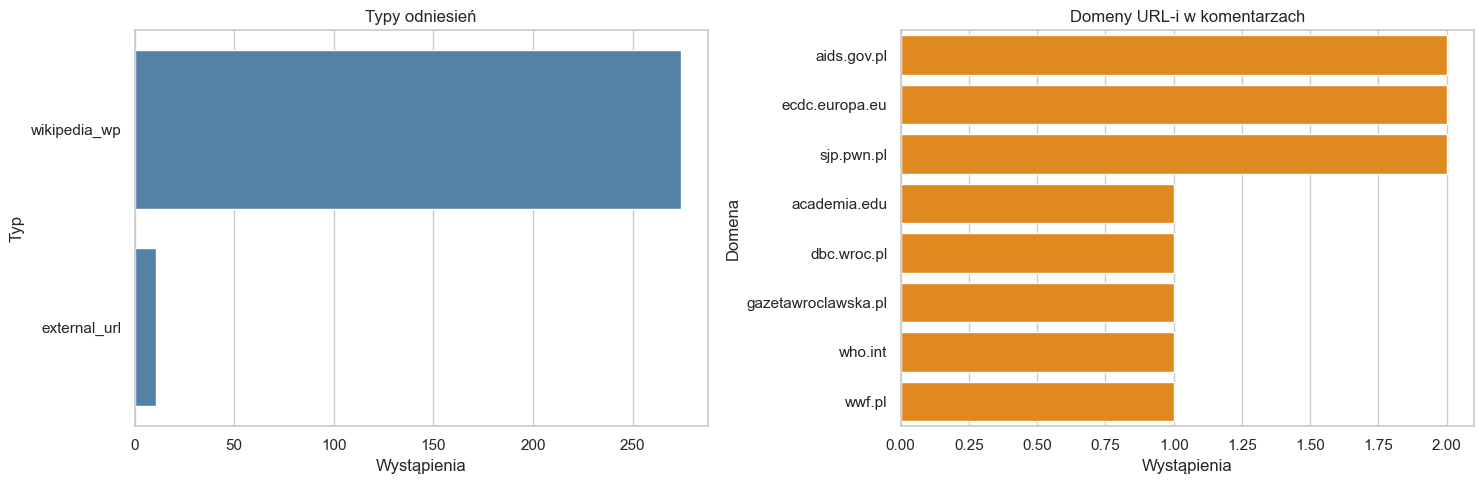

In [11]:
if not references_df.empty:
    reference_type_summary = (
        references_df.groupby("reference_type", as_index=False)
        .agg(occurrences=("reference", "size"), unique_references=("reference", "nunique"))
        .sort_values("occurrences", ascending=False)
    )
    domain_summary = (
        references_df[references_df["reference_type"] == "external_url"]
        .groupby("domain", as_index=False)
        .agg(occurrences=("reference", "size"), unique_urls=("reference", "nunique"))
        .sort_values("occurrences", ascending=False)
    )
    display(reference_type_summary)
    display(domain_summary)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.barplot(data=reference_type_summary, y="reference_type", x="occurrences", ax=axes[0], color="steelblue")
    axes[0].set(title="Typy odniesień", xlabel="Wystąpienia", ylabel="Typ")
    if not domain_summary.empty:
        sns.barplot(data=domain_summary.head(15), y="domain", x="occurrences", ax=axes[1], color="darkorange")
    axes[1].set(title="Domeny URL-i w komentarzach", xlabel="Wystąpienia", ylabel="Domena")
    plt.tight_layout()
else:
    print("Nie znaleziono URL-i ani skrótów WP/WPT/WT w komentarzach.")

## Model klasyfikacji źródeł i sposobu powołania

Bazowa ekstrakcja wykrywała adresy URL oraz skróty Wikipedii. Poniższy lokalny model hybrydowy dodaje klasyfikację domen i nazw instytucji, sygnały językowe (np. „według”, „źródło”, „badania”) oraz fragment kontekstu. `confidence` jest oceną heurystyczną dopasowania, a nie prawdopodobieństwem modelu. Warto pamiętać, że w tym zbiorze `comment` oznacza komentarz edycji Wikipedii, a nie komentarz dyskusyjny użytkownika.

In [12]:
import re
import pandas as pd
from urllib.parse import urlsplit

SOURCE_CATEGORIES = {
    "instytucje publiczne": ["gov.pl", "who.int", "ecdc.europa.eu", "aids.gov.pl", "nfz", "gis", "gus", "ministerstwo", "urząd"],
    "nauka i edukacja": ["doi.org", "pubmed", "nature.com", "science.org", "academia.edu", "pwn.pl", "uniwersytet", "uniwersytetu", "instytut"],
    "media": ["gazeta", "tvn", "tvp", "polsat", "onet", "wp.pl", "interia", "bbc", "reuters", "guardian"],
    "organizacje społeczne i środowiskowe": ["wwf", "greenpeace", "fundacja", "stowarzyszenie", "ngo"],
    "źródła encyklopedyczne": ["wikipedia.org", "wikimedia.org", "wikiwand"],
    "źródła osobiste": ["moje doświadczenie", "z własnego doświadczenia", "widziałem", "widziałam", "pamiętam", "mój przypadek", "użytkownik"],
}
SOURCE_CUES = re.compile(r"\b(według|źródło|źródła|badania|badanie|raport|dane|artykuł|publikacja|jak podaje|podaje|link|cytuję|opublikowano)\b", re.IGNORECASE)
DOMAIN_PATTERN = re.compile(r"https?://[^\s\]})>,]+", re.IGNORECASE)
wiki_reference_pattern = re.compile(r"\[\[(?P<namespace>WP|WPT|WT):(?P<title>[^\]|]+)(?:\|[^\]]*)?\]\]", re.IGNORECASE)

def classify_source(reference, domain, comment):
    haystack = f"{reference} {domain} {comment}".casefold()
    for category, terms in SOURCE_CATEGORIES.items():
        if any(term.casefold() in haystack for term in terms):
            return category, 0.90
    if domain:
        return "inna domena zewnętrzna", 0.80
    if SOURCE_CUES.search(comment):
        return "powołanie bez wskazanego źródła", 0.55
    return "odniesienie techniczne Wikipedii", 0.95

semantic_references = []
comment_mask = df["comment"].fillna("").astype(str).str.strip().ne("")
for row in df.loc[comment_mask].itertuples(index=False):
    comment = row.comment
    matches = [(match, "url") for match in DOMAIN_PATTERN.finditer(comment)]
    matches += [(match, "wiki") for match in wiki_reference_pattern.finditer(comment)]
    if not matches and SOURCE_CUES.search(comment):
        category, confidence = classify_source("", "", comment)
        semantic_references.append({"page": row.page, "revision_number": row.revision_number, "comment": comment, "reference": "niesprecyzowane źródło", "domain": "", "source_category": category, "confidence": confidence, "cue": SOURCE_CUES.search(comment).group(0)})
    for match, match_type in matches:
        if match_type == "url":
            reference = match.group(0).rstrip(".,;:!?\"")
            domain = urlsplit(reference).netloc.lower().removeprefix("www.")
        else:
            reference = f"{match.group('namespace').upper()}:{match.group('title').strip()}"
            domain = "wikipedia.org"
        cue_match = SOURCE_CUES.search(comment)
        category, confidence = classify_source(reference, domain, comment)
        semantic_references.append({"page": row.page, "revision_number": row.revision_number, "comment": comment, "reference": reference, "domain": domain, "source_category": category, "confidence": confidence, "cue": cue_match.group(0) if cue_match else ""})

semantic_references_df = pd.DataFrame(semantic_references)
if semantic_references_df.empty:
    print("Nie wykryto odniesień możliwych do sklasyfikowania.")
else:
    semantic_references_df = semantic_references_df.drop_duplicates(["page", "revision_number", "reference", "source_category"])
    semantic_quality = pd.Series({
        "komentarze z odniesieniem": semantic_references_df[["page", "revision_number"]].drop_duplicates().shape[0],
        "wystąpienia po deduplikacji": len(semantic_references_df),
        "unikalne źródła": semantic_references_df["reference"].nunique(),
        "średnia pewność": semantic_references_df["confidence"].mean(),
    })
    display(semantic_quality.to_frame("wartość").round(2))
    display(semantic_references_df.head(20))

,wartość
komentarze z odniesieniem,370.00
wystąpienia po deduplikacji,485.00
unikalne źródła,39.00
średnia pewność,0.76


,page,revision_number,comment,reference,domain,source_category,confidence,cue
0,COVID-19,3,"[[WP:SK]], drobne techniczne",WP:SK,wikipedia.org,źródła encyklopedyczne,0.90,
1,COVID-19,6,"drobne redakcyjne, [[Pomoc:Słowniczek#W|wikizacja]], drobne techniczne, źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
2,COVID-19,8,"drobne redakcyjne, źródła/przypisy, int.",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
3,COVID-19,11,"akt., drobne redakcyjne, źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
4,COVID-19,12,"drobne redakcyjne, akt., źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
5,COVID-19,14,"drobne redakcyjne, źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
6,COVID-19,17,MalarzBOT: WPCHECK#64: poprawiam link tożsamy z tekstem linka,niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,link
7,COVID-19,20,"akt., drobne redakcyjne, źródła/przypisy, [[Pomoc:Słowniczek#W|wikizacja]], int., ilustracja, infobox, korekta",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
8,COVID-19,22,"akt., źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła
9,COVID-19,23,"akt., źródła/przypisy",niesprecyzowane źródło,,powołanie bez wskazanego źródła,0.55,źródła


,odniesienia,unikalne_źródła,komentarze,średnia_pewność
source_category,,,,
źródła encyklopedyczne,271,28,136,0.90
powołanie bez wskazanego źródła,197,1,155,0.55
instytucje publiczne,6,5,6,0.90
media,4,4,4,0.90
nauka i edukacja,4,4,4,0.90
organizacje społeczne i środowiskowe,2,2,2,0.90
inna domena zewnętrzna,1,1,1,0.80


,source_category,domain,odniesienia
10,źródła encyklopedyczne,wikipedia.org,271
1,instytucje publiczne,aids.gov.pl,2
2,instytucje publiczne,ecdc.europa.eu,2
5,media,wikipedia.org,2
7,nauka i edukacja,sjp.pwn.pl,2
0,inna domena zewnętrzna,dbc.wroc.pl,1
3,instytucje publiczne,who.int,1
4,media,gazetawroclawska.pl,1
6,nauka i edukacja,academia.edu,1
8,nauka i edukacja,wikipedia.org,1


,page,source_category,odniesienia
4,COVID-19,źródła encyklopedyczne,84
3,COVID-19,powołanie bez wskazanego źródła,83
12,Kwas askorbinowy,źródła encyklopedyczne,45
26,Zesp%C3%B3%C5%82 nabytego niedoboru odporno%C5%9Bci,źródła encyklopedyczne,39
10,Globalne ocieplenie,źródła encyklopedyczne,31
21,Szczepionka,źródła encyklopedyczne,28
11,Kwas askorbinowy,powołanie bez wskazanego źródła,25
14,Lekarz,powołanie bez wskazanego źródła,24
20,Szczepionka,powołanie bez wskazanego źródła,24
9,Globalne ocieplenie,powołanie bez wskazanego źródła,24


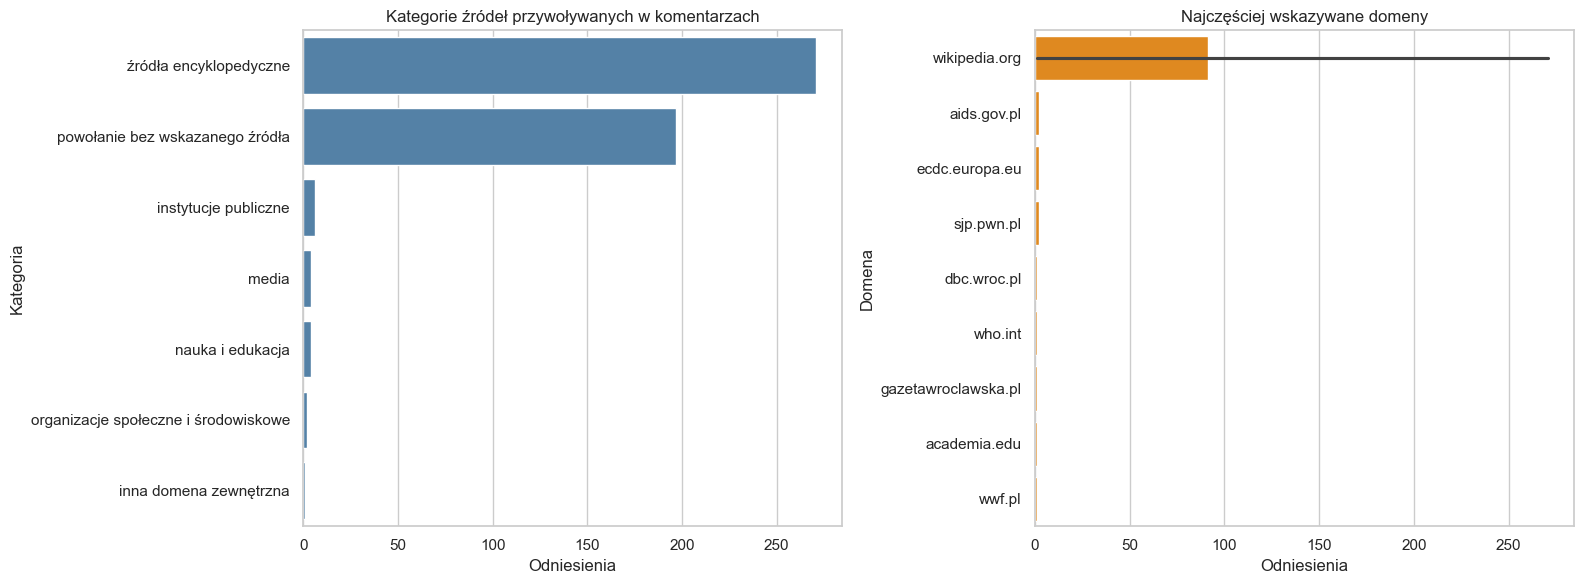

,page,source_category,reference,cue,comment
0,COVID-19,źródła encyklopedyczne,WP:SK,,"[[WP:SK]], drobne techniczne"
1,Lekarz,nauka i edukacja,WP:POP,,[[WP:POP|Popups]]: Ujednoznacznienie linku z [[Collegium Medicum]] na [[Collegium Medicum Uniwersytetu Jagiellońskie...
2,Globalne ocieplenie,organizacje społeczne i środowiskowe,https://www.wwf.pl/srodowisko/klimat?gclid=Cj0KCQiAvJXxBRCeARIsAMSkAprscLWXfLwIDW2c30tKWfHQTB28DkickCU1Un511d2uCMnN5...,,https://www.wwf.pl/srodowisko/klimat?gclid=Cj0KCQiAvJXxBRCeARIsAMSkAprscLWXfLwIDW2c30tKWfHQTB28DkickCU1Un511d2uCMnN5...
3,Globalne ocieplenie,instytucje publiczne,niesprecyzowane źródło,Artykuł,"/* Ograniczenie *[[File:The Rodney & Otamatea - AUGUST 14, 1912.jpg|thumb|Artykuł w nowozelandzkiej gazecie (opublik..."
4,Globalne ocieplenie,media,niesprecyzowane źródło,źródła,"zamiana źródła z TVP.INFO na artykuł w [[Nature]] który był opisywany, drobne merytoryczne za abstraktem artykułu"
5,Medycyna,inna domena zewnętrzna,https://dbc.wroc.pl/Content/2026/PDF/wprowadzenie_do_medycyny.pdf,Link,"/* Nauki podstawowe medycyny */ Cytując z publikacji wprowadzenie do medycyny ""Medycynę zalicza się do nauk przyrodn..."
6,COVID-19,powołanie bez wskazanego źródła,niesprecyzowane źródło,źródło,Toss a źródło! Anulowanie wersji 59073366 autorstwa [[Special:Contributions/Szymigiusz|Szymigiusz]] ([[User talk:Szy...


In [13]:
if not semantic_references_df.empty:
    source_category_summary = (
        semantic_references_df.groupby("source_category")
        .agg(odniesienia=("reference", "size"), unikalne_źródła=("reference", "nunique"), komentarze=("revision_number", "nunique"), średnia_pewność=("confidence", "mean"))
        .sort_values("odniesienia", ascending=False)
    )
    source_by_page = (
        semantic_references_df.groupby(["page", "source_category"])
        .size().rename("odniesienia").reset_index()
        .sort_values("odniesienia", ascending=False)
    )
    top_sources = (
        semantic_references_df[semantic_references_df["domain"].ne("")]
        .groupby(["source_category", "domain"]).size().rename("odniesienia").reset_index()
        .sort_values("odniesienia", ascending=False).head(25)
    )
    display(source_category_summary.round(2))
    display(top_sources)
    display(source_by_page.head(30))

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.barplot(data=source_category_summary.reset_index(), y="source_category", x="odniesienia", ax=axes[0], color="steelblue")
    axes[0].set(title="Kategorie źródeł przywoływanych w komentarzach", xlabel="Odniesienia", ylabel="Kategoria")
    if not top_sources.empty:
        sns.barplot(data=top_sources.head(15), y="domain", x="odniesienia", ax=axes[1], color="darkorange")
    axes[1].set(title="Najczęściej wskazywane domeny", xlabel="Odniesienia", ylabel="Domena")
    plt.tight_layout()
    plt.show()

    examples = semantic_references_df.sort_values("confidence", ascending=False).drop_duplicates("source_category")
    display(examples[["page", "source_category", "reference", "cue", "comment"]].reset_index(drop=True))
else:
    print("Brak wyników do agregacji.")